# Entrega 3 — Chunking de Manifestações Longas
**Ouvidoria Inteligente: Triagem Semântica de Manifestações Cidadãs**  
**Aluno:** Ricardo Silva Flores

Este notebook seleciona as cinco manifestações mais longas, compara duas configurações de chunking e visualiza os chunks em duas dimensões.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from langchain_text_splitters import RecursiveCharacterTextSplitter
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

with open('manifestacoes.json', 'r', encoding='utf-8') as arquivo:
    manifestacoes = json.load(arquivo)

df = pd.DataFrame(manifestacoes)
df['tamanho_caracteres'] = df['texto'].str.len()
longas = df.nlargest(5, 'tamanho_caracteres').copy()
longas[['id', 'categoria_oficial', 'tamanho_caracteres']]

C:\Users\PICHAU\Documents\facul\8periodo\ricardo\OuvidoriaInteligente\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,id,categoria_oficial,tamanho_caracteres
39,M040,educação,958
34,M035,segurança,935
24,M025,saúde,922
14,M015,segurança,786
4,M005,saúde,691


In [2]:
configuracoes = [
    {'nome': 'Configuração A', 'chunk_size': 300, 'chunk_overlap': 40},
    {'nome': 'Configuração B', 'chunk_size': 420, 'chunk_overlap': 100},
]

def dividir_em_chunks(texto, chunk_size, chunk_overlap):
    divisor = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        separators=['\n\n', '\n', '. ', ' ', '']
    )
    return divisor.split_text(texto)

resumo = []
for _, linha in longas.iterrows():
    for config in configuracoes:
        chunks = dividir_em_chunks(linha['texto'], config['chunk_size'], config['chunk_overlap'])
        resumo.append({
            'Manifestação': linha['id'],
            'Configuração': config['nome'],
            'chunk_size': config['chunk_size'],
            'chunk_overlap': config['chunk_overlap'],
            'Quantidade de chunks': len(chunks),
            'Tamanho dos chunks': [len(chunk) for chunk in chunks],
        })

pd.DataFrame(resumo)

,Manifestação,Configuração,chunk_size,chunk_overlap,Quantidade de chunks,Tamanho dos chunks
0,M040,Configuração A,300,40,4,"[282, 243, 230, 203]"
1,M040,Configuração B,420,100,4,"[282, 243, 230, 203]"
2,M035,Configuração A,300,40,4,"[127, 229, 298, 281]"
3,M035,Configuração B,420,100,3,"[356, 298, 380]"
4,M025,Configuração A,300,40,4,"[266, 218, 162, 276]"
5,M025,Configuração B,420,100,3,"[266, 380, 276]"
6,M015,Configuração A,300,40,4,"[116, 222, 259, 189]"
7,M015,Configuração B,420,100,3,"[338, 259, 189]"
8,M005,Configuração A,300,40,3,"[267, 272, 152]"
9,M005,Configuração B,420,100,3,"[267, 272, 238]"


In [3]:
# Exemplo detalhado com a manifestação longa M005 e as duas configurações.
exemplo = longas.iloc[0]
print('Manifestação selecionada:', exemplo['id'])
print('Tamanho:', exemplo['tamanho_caracteres'], 'caracteres')

for config in configuracoes:
    print('\n' + '=' * 80)
    print(config['nome'], '| chunk_size =', config['chunk_size'], '| overlap =', config['chunk_overlap'])
    partes = dividir_em_chunks(exemplo['texto'], config['chunk_size'], config['chunk_overlap'])
    for numero, parte in enumerate(partes, start=1):
        print(f'\nChunk {numero} ({len(parte)} caracteres):\n{parte}')

Manifestação selecionada: M040
Tamanho: 958 caracteres

Configuração A | chunk_size = 300 | overlap = 40

Chunk 1 (282 caracteres):
Gostaria de expor uma situação preocupante na Escola Municipal Villa-Lobos, localizada no bairro Novo Horizonte. A escola não possui rampa de acesso adequada nem banheiro adaptado para alunos com deficiência física, o que fere claramente o direito à acessibilidade garantido por lei

Chunk 2 (243 caracteres):
. Minha filha, que utiliza cadeira de rodas, estuda no período da manhã e enfrenta dificuldades diárias para se locomover entre as salas de aula, principalmente no bloco onde fica o laboratório de informática, que só é acessível por uma escada

Chunk 3 (230 caracteres):
. Além disso, o banheiro reservado para pessoas com deficiência está interditado há mais de um ano por problemas na estrutura hidráulica, obrigando minha filha a se deslocar até outro prédio, o que consome um tempo valioso de aula

Chunk 4 (203 caracteres):
. Já protocolamos um pedido f

In [4]:
# Mede coesão usando embeddings e similaridade entre chunks consecutivos.
modelo = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')

tabelas_coesao = []
for config in configuracoes:
    partes = dividir_em_chunks(exemplo['texto'], config['chunk_size'], config['chunk_overlap'])
    vetores = modelo.encode(partes, show_progress_bar=False)
    matriz = cosine_similarity(vetores)
    for i in range(len(partes) - 1):
        tabelas_coesao.append({
            'Configuração': config['nome'],
            'Pares': f'Chunk {i + 1} × Chunk {i + 2}',
            'Similaridade consecutiva': round(float(matriz[i, i + 1]), 4),
        })

pd.DataFrame(tabelas_coesao)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3491.50it/s]


,Configuração,Pares,Similaridade consecutiva
0,Configuração A,Chunk 1 × Chunk 2,0.4681
1,Configuração A,Chunk 2 × Chunk 3,0.5574
2,Configuração A,Chunk 3 × Chunk 4,0.3311
3,Configuração B,Chunk 1 × Chunk 2,0.4681
4,Configuração B,Chunk 2 × Chunk 3,0.5574
5,Configuração B,Chunk 3 × Chunk 4,0.3311


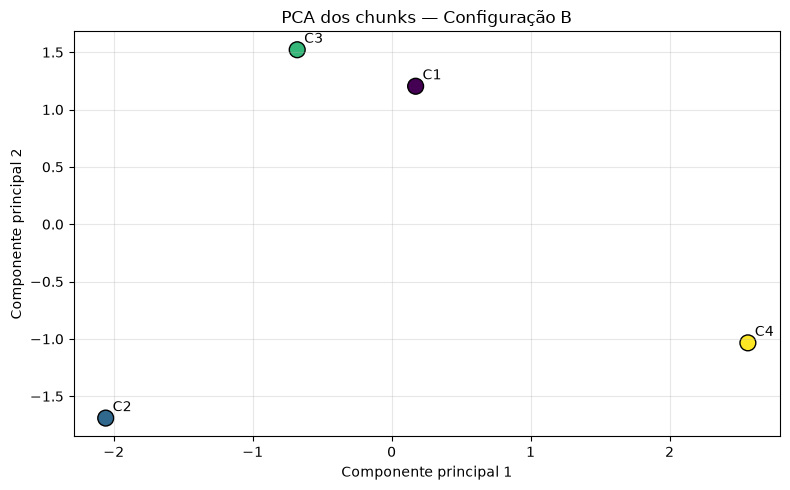

In [5]:
# PCA dos chunks usando a configuração B, que possui overlap maior.
config_visual = configuracoes[1]
partes = dividir_em_chunks(exemplo['texto'], config_visual['chunk_size'], config_visual['chunk_overlap'])
vetores = modelo.encode(partes, show_progress_bar=False)
pontos = PCA(n_components=2).fit_transform(vetores)

figura, eixo = plt.subplots(figsize=(8, 5))
eixo.scatter(pontos[:, 0], pontos[:, 1], c=range(len(partes)), cmap='viridis', s=130, edgecolors='black')
for i in range(len(partes)):
    eixo.annotate(f'C{i + 1}', (pontos[i, 0], pontos[i, 1]), xytext=(5, 5), textcoords='offset points')
eixo.set_title(f'PCA dos chunks — {config_visual["nome"]}')
eixo.set_xlabel('Componente principal 1')
eixo.set_ylabel('Componente principal 2')
eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Discussão
O overlap reduz a perda de contexto nas fronteiras dos blocos: informações presentes no fim de um chunk reaparecem no início do próximo. A configuração A, com blocos menores e overlap de 40 caracteres, produz mais chunks e é útil para recuperação pontual, mas pode fragmentar ideias extensas. A configuração B, com blocos de 420 caracteres e overlap de 100, tende a preservar melhor denúncias longas, pois mantém frases e relações entre causa, consequência e pedido de providência.

A tabela de similaridades consecutivas e o gráfico PCA devem ser usados para confirmar essa interpretação com os valores da execução. Espera-se que chunks da mesma manifestação fiquem relativamente próximos, especialmente quando existe sobreposição.